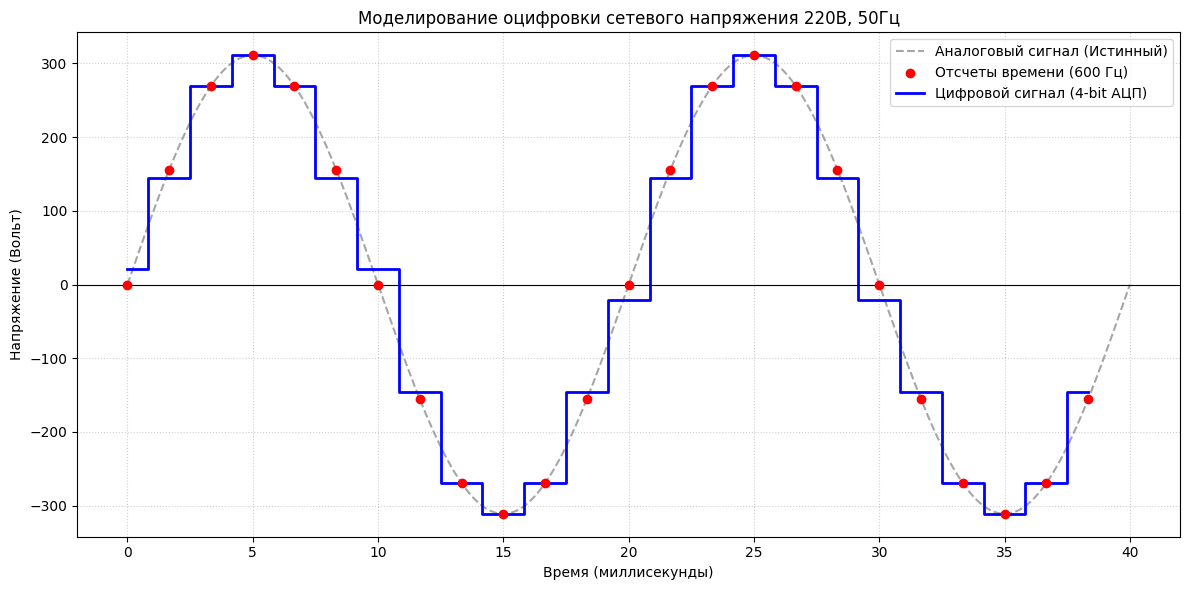

Период сигнала: 20.0 мс
Интервал между замерами АЦП: 1.67 мс
Всего получено цифровых точек за 40 мс: 24

Первые 5 цифровых отсчетов (Время, мс -> Напряжение, В):
   0.00 мс  ->    20.7 В
   1.67 мс  ->   145.2 В
   3.33 мс  ->   269.6 В
   5.00 мс  ->   311.1 В
   6.67 мс  ->   269.6 В


In [1]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. ИСХОДНЫЕ ПАРАМЕТРЫ СИГНАЛА И СЕТИ
# ==========================================
f_signal = 50  # Частота переменного тока в РФ (50 Гц)
U_rms = 220  # Действующее (фазное) напряжение (Вольт)
U_max = U_rms * np.sqrt(2)  # Амплитудное напряжение (~311.13 В)

# ==========================================
# 2. ПАРАМЕТРЫ ДИСКРЕТИЗАЦИИ И КВАНТОВАНИЯ
# ==========================================
# Частота дискретизации (сэмплирования). По теореме Котельникова должна быть > 100 Гц.
# Возьмем 600 Гц (12 точек на один период в 50 Гц), чтобы наглядно видеть "шаги".
f_sampling = 600
t_start = 0
t_end = 0.04  # Моделируем 0.04 секунды (ровно 2 полных периода сигнала)

# Разрядность АЦП для квантования по уровню (например, 4 бита для наглядности ступенек)
adc_bits = 4
quantization_levels = 2**adc_bits  # 16 уровней напряжения

# ==========================================
# 3. МОДЕЛИРОВАНИЕ
# ==========================================

# А. Непрерывный (аналоговый) сигнал - генерируем очень плотную сетку точек
t_analog = np.linspace(t_start, t_end, 1000)
u_analog = U_max * np.sin(2 * np.pi * f_signal * t_analog)

# Б. Дискретизация по времени (Сэмплирование)
t_sampled = np.arange(t_start, t_end, 1 / f_sampling)
u_sampled = U_max * np.sin(2 * np.pi * f_signal * t_sampled)

# В. Квантование по уровню (АЦП)
# Нормализуем сигнал от -U_max..U_max к диапазону уровней АЦП (0 .. levels-1)
u_min, u_max_range = -U_max, U_max
u_normalized = (u_sampled - u_min) / (u_max_range - u_min)  # В диапазон [0, 1]

# Округляем до ближайшего целого уровня квантования
u_quantized_labels = np.round(u_normalized * (quantization_levels - 1))

# Переводим обратно в Вольты для отображения на графике
u_digital = (
    u_quantized_labels / (quantization_levels - 1) * (u_max_range - u_min)
    + u_min
)

# ==========================================
# 4. ВИЗУАЛИЗАЦИЯ
# ==========================================
plt.figure(figsize=(12, 6))

# Рисуем идеальный аналоговый сигнал
plt.plot(
    t_analog * 1000,
    u_analog,
    label="Аналоговый сигнал (Истинный)",
    color="gray",
    linestyle="--",
    alpha=0.7,
)

# Рисуем точки дискретизации (сэмплы)
plt.scatter(
    t_sampled * 1000,
    u_sampled,
    color="red",
    zorder=5,
    label=f"Отсчеты времени ({f_sampling} Гц)",
)

# Рисуем итоговый цифровой ступенчатый сигнал (Квантование)
plt.step(
    t_sampled * 1000,
    u_digital,
    where="mid",
    color="blue",
    linewidth=2,
    label=f"Цифровой сигнал ({adc_bits}-bit АЦП)",
)

# Настройки осей и сетки
plt.title(
    f"Моделирование оцифровки сетевого напряжения {U_rms}В, {f_signal}Гц"
)
plt.xlabel("Время (миллисекунды)")
plt.ylabel("Напряжение (Вольт)")
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(loc="upper right")

# Показываем график
plt.tight_layout()
plt.show()


# ==========================================
# 5. ВЫВОД ДАННЫХ В КОНСОЛЬ
# ==========================================
print(f"Период сигнала: {1/f_signal * 1000:.1f} мс")
print(f"Интервал между замерами АЦП: {1/f_sampling * 1000:.2f} мс")
print(
    f"Всего получено цифровых точек за {t_end*1000:.0f} мс: {len(u_digital)}"
)
print("\nПервые 5 цифровых отсчетов (Время, мс -> Напряжение, В):")
for t, val in zip(t_sampled[:5], u_digital[:5]):
    print(f"  {t*1000:5.2f} мс  ->  {val:6.1f} В")


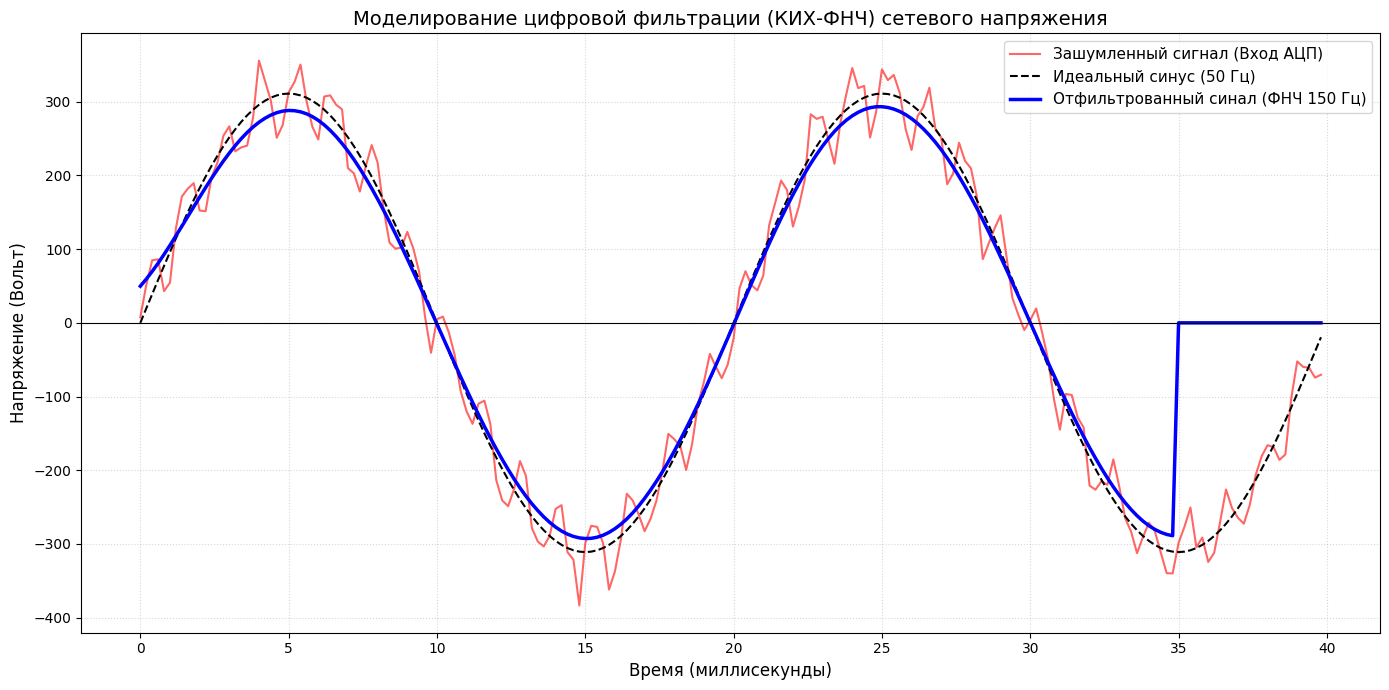

Истинное действующее напряжение сети: 220.0 В
Действующее значение ЗАШУМЛЕННОГО сигнала: 220.6 В (Ошибка из-за шума!)
Действующее значение после ФИЛЬТРАЦИИ: 205.5 В (Точность восстановлена)


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import firwin, lfilter

# ==========================================
# 1. ИСХОДНЫЕ ПАРАМЕТРЫ СИГНАЛА И ШУМА
# ==========================================
f_signal = 50  # Полезный сигнал (сетевая частота 50 Гц)
U_rms = 220  # Действующее напряжение
U_max = U_rms * np.sqrt(2)  # Амплитуда (~311 В)

f_noise = 800  # Высокочастотная помеха (например, от импульсного блока питания)
U_noise = 40  # Амплитуда шума (40 В)

# ==========================================
# 2. ПАРАМЕТРЫ ДИСКРЕТИЗАЦИИ И ФИЛЬТРАЦcontrol
# ==========================================
# Берем высокую частоту дискретизации, чтобы качественно отцифровать и сигнал, и шум
f_sampling = 5000  # 5 кГц
t_start = 0
t_end = 0.04  # 2 полных периода сети (40 мс)

t = np.arange(t_start, t_end, 1 / f_sampling)

# ==========================================
# 3. МОДЕЛИРОВАНИЕ СИГНАЛА С ПОМЕХАМИ
# ==========================================
# Чистый идеальный синус
u_clean = U_max * np.sin(2 * np.pi * f_signal * t)

# Добавляем случайный белый шум + конкретную ВЧ-наводку 800 Гц
np.random.seed(42)  # Для воспроизводимости случайного шума
white_noise = np.random.normal(0, 15, len(t))
u_noise_component = U_noise * np.sin(2 * np.pi * f_noise * t)

# Итоговый зашумленный сигнал, который «видит» АЦП осциллографа
u_noisy = u_clean + u_noise_component + white_noise

# ==========================================
# 4. ЦИФРОВАЯ ФИЛЬТРАЦИЯ (КИХ / FIR ФНЧ)
# ==========================================
# Задаем параметры фильтра
num_taps = 51  # Количество коэффициентов (длина фильтра)
f_cutoff = 150  # Частота среза 150 Гц (все что выше — подавляем)

# Рассчитываем коэффициенты КИХ-фильтра методом окон (используется окно Хэмминга)
# Обязательно передаем частоту Найквиста (f_sampling / 2) для нормализации
fir_coefficients = firwin(num_taps, f_cutoff, fs=f_sampling)

# Пропускаем зашумленный массив через фильтр (цифровая свертка)
u_filtered = lfilter(fir_coefficients, 1.0, u_noisy)

# Корректируем фазовый сдвиг (КИХ-фильтр задерживает сигнал ровно на (num_taps - 1) / 2 отсчетов)
delay = (num_taps - 1) // 2
u_filtered_aligned = np.zeros_like(u_filtered)
u_filtered_aligned[:-delay] = u_filtered[
    delay:
]  # Сдвигаем график влево для выравнивания фазы

# ==========================================
# 5. ВИЗУАЛИЗАЦИЯ
# ==========================================
plt.figure(figsize=(14, 7))

# 1. Зашумленный сигнал с АЦП
plt.plot(
    t * 1000,
    u_noisy,
    color="red",
    alpha=0.6,
    label="Зашумленный сигнал (Вход АЦП)",
)

# 2. Идеальный чистый синус для сравнения
plt.plot(
    t * 1000,
    u_clean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Идеальный синус (50 Гц)",
)

# 3. Сигнал после КИХ-фильтра
plt.plot(
    t * 1000,
    u_filtered_aligned,
    color="blue",
    linewidth=2.5,
    label=f"Отфильтрованный синал (ФНЧ {f_cutoff} Гц)",
)

# Оформление графика
plt.title(
    f"Моделирование цифровой фильтрации (КИХ-ФНЧ) сетевого напряжения",
    fontsize=14,
)
plt.xlabel("Время (миллисекунды)", fontsize=12)
plt.ylabel("Напряжение (Вольт)", fontsize=12)
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(loc="upper right", fontsize=11)

plt.tight_layout()
plt.show()

# ==========================================
# 6. АНАЛИЗ РЕЗУЛЬТАТОВ (ЦОС)
# ==========================================
# Считаем действующее напряжение (RMS) до и после фильтрации
rms_noisy = np.sqrt(np.mean(u_noisy**2))
rms_filtered = np.sqrt(
    np.mean(u_filtered_aligned[:-delay] ** 2)
)  # исключаем хвост задержки

print(f"Истинное действующее напряжение сети: {U_rms:.1f} В")
print(
    f"Действующее значение ЗАШУМЛЕННОГО сигнала: {rms_noisy:.1f} В (Ошибка из-за шума!)"
)
print(
    f"Действующее значение после ФИЛЬТРАЦИИ: {rms_filtered:.1f} В (Точность восстановлена)"
)


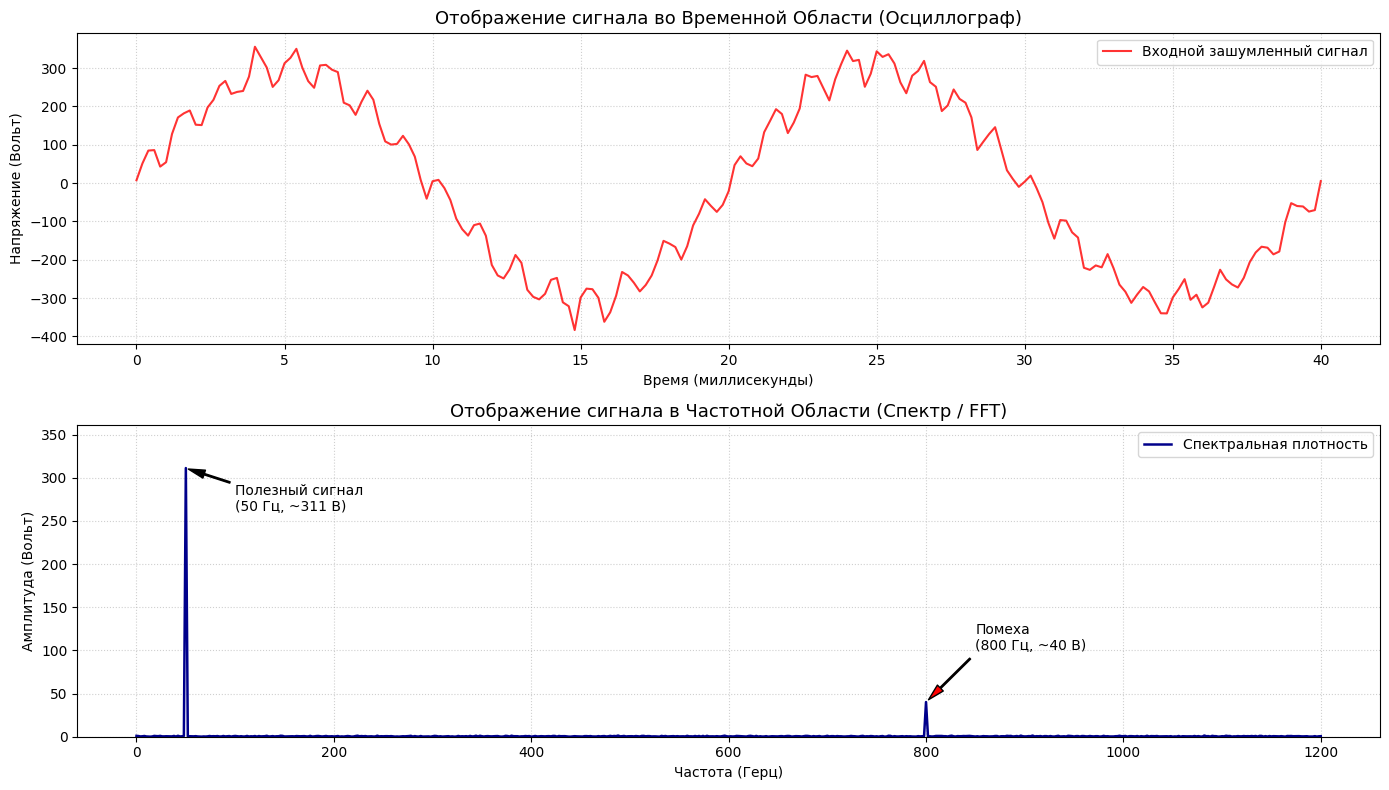

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. СИГНАЛ И ШУМ (КОПИРУЕМ ИЗ ПРОШЛОГО ШАГА)
# ==========================================
f_signal = 50  # Полезный сигнал 50 Гц
U_max = 220 * np.sqrt(2)  # ~311 В

f_noise = 800  # Помеха 800 Гц
U_noise = 40  # 40 В

f_sampling = 5000  # Частота дискретизации 5 кГц
t_start = 0
t_end = 0.5  # Берем интервал чуть больше (500 мс), чтобы спектр получился очень четким

t = np.arange(t_start, t_end, 1 / f_sampling)
N = len(t)  # Общее количество оцифрованных точек (сэмплов)

# Генерируем зашумленный сигнал
np.random.seed(42)
white_noise = np.random.normal(0, 15, N)
u_noisy = (
    U_max * np.sin(2 * np.pi * f_signal * t)
    + U_noise * np.sin(2 * np.pi * f_noise * t)
    + white_noise
)

# ==========================================
# 2. БЫСТРОЕ ПРЕОБРАЗОВАНИЕ ФУРЬЕ (FFT)
# ==========================================
# Выполняем само преобразование Фурье
# На выходе получаем массив комплексных чисел, содержащих информацию об амплитуде и фазе
fft_result = np.fft.fft(u_noisy)

# Рассчитываем шкалу частот для оси X
# По закону Найквиста спектр зеркален, поэтому берем только первую половину частот (до f_sampling / 2)
frequencies = np.fft.fftfreq(N, 1 / f_sampling)[: N // 2]

# Находим амплитуды спектра (модуль комплексного числа)
# Умножаем на 2/N для нормировки амплитуды (восстановления реальных Вольт)
fft_amplitudes = (2.0 / N) * np.abs(fft_result)[: N // 2]

# ==========================================
# 3. ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

# График 1: Сигнал во времени (обычный экран осциллографа)
# Покажем только первые 40 мс для наглядности
mask_time = t <= 0.04
ax1.plot(
    t[mask_time] * 1000,
    u_noisy[mask_time],
    color="red",
    alpha=0.8,
    label="Входной зашумленный сигнал",
)
ax1.set_title("Отображение сигнала во Временной Области (Осциллограф)", fontsize=13)
ax1.set_xlabel("Время (миллисекунды)")
ax1.set_ylabel("Напряжение (Вольт)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# График 2: Спектр частот (Режим FFT / Анализатор спектра)
# Ограничим ось X до 1200 Гц, так как всё самое интересное находится там
mask_freq = frequencies <= 1200
ax2.plot(
    frequencies[mask_freq],
    fft_amplitudes[mask_freq],
    color="darkblue",
    linewidth=1.8,
    label="Спектральная плотность",
)

# Подписываем пики на графике спектра
ax2.annotate(
    f"Полезный сигнал\n({f_signal} Гц, ~{U_max:.0f} В)",
    xy=(f_signal, U_max),
    xytext=(f_signal + 50, U_max - 50),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
)
ax2.annotate(
    f"Помеха\n({f_noise} Гц, ~{U_noise} В)",
    xy=(f_noise, U_noise),
    xytext=(f_noise + 50, U_noise + 60),
    arrowprops=dict(facecolor="red", shrink=0.05, width=1, headwidth=6),
)

ax2.set_title(
    "Отображение сигнала в Частотной Области (Спектр / FFT)", fontsize=13
)
ax2.set_xlabel("Частота (Герц)")
ax2.set_ylabel("Амплитуда (Вольт)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.set_ylim(0, U_max + 50)
ax2.legend()

plt.tight_layout()
plt.show()


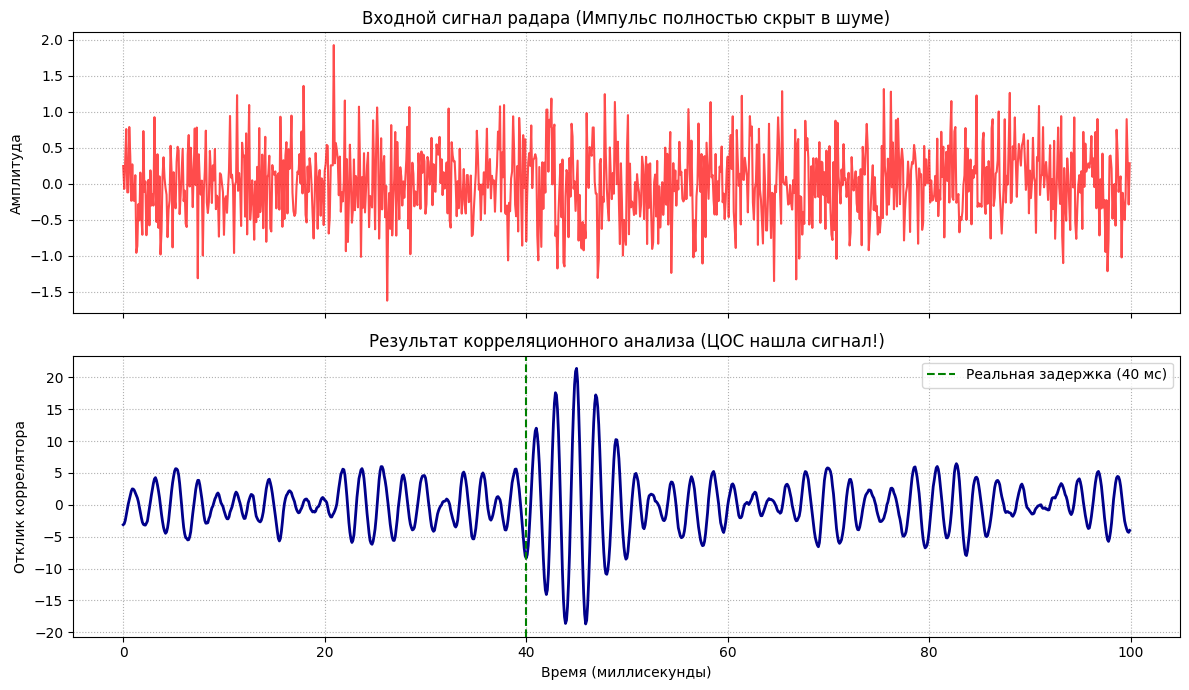

In [8]:

# 1. Параметры симуляции
f_sampling = 10000  # 10 кГц
t = np.arange(0, 0.1, 1 / f_sampling)  # 100 мс общего времени

# Создаем шаблон импульса (например, зондирующий сигнал радара - пачка синуса 500 Гц)
t_pulse = np.arange(0, 0.01, 1 / f_sampling)  # Длительность импульса 10 мс
pulse_template = np.sin(2 * np.pi * 500 * t_pulse)

# 2. Формируем принятый сигнал (Эхо вернулось через 40 мс)
received_signal = np.zeros_like(t)
delay_index = int(0.04 * f_sampling)  # Индекс, соответствующий 40 мс
received_signal[delay_index : delay_index + len(pulse_template)] = (
    pulse_template * 0.5
)  # Ослабленное эхо

# Добавляем ОГРОМНЫЙ шум (сигнал буквально тонет в нем)
np.random.seed(42)
noise = np.random.normal(0, .5, len(t))
u_noisy_received = received_signal + noise

# 3. АЛГОРИТМ ЦОС: Взаимная корреляция (Cross-correlation)
# Функция correlate "двигает" шаблон по зашумленному сигналу и перемножает их
correlation = np.convolve(
    u_noisy_received, pulse_template[::-1], mode="same"
)

# ==========================================
# 4. ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Верхний график: Что видит АЦП радара
ax1.plot(t * 1000, u_noisy_received, color="red", alpha=0.7)
ax1.set_title("Входной сигнал радара (Импульс полностью скрыт в шуме)")
ax1.set_ylabel("Амплитуда")
ax1.grid(True, linestyle=":")

# Нижний график: Результат работы коррелятора
ax2.plot(t * 1000, correlation, color="darkblue", linewidth=2)
ax2.axvline(40, color="green", linestyle="--", linewidth=1.5, label="Реальная задержка (40 мс)")
ax2.set_title("Результат корреляционного анализа (ЦОС нашла сигнал!)")
ax2.set_xlabel("Время (миллисекунды)")
ax2.set_ylabel("Отклик коррелятора")
ax2.grid(True, linestyle=":")
ax2.legend()

plt.tight_layout()
plt.show()


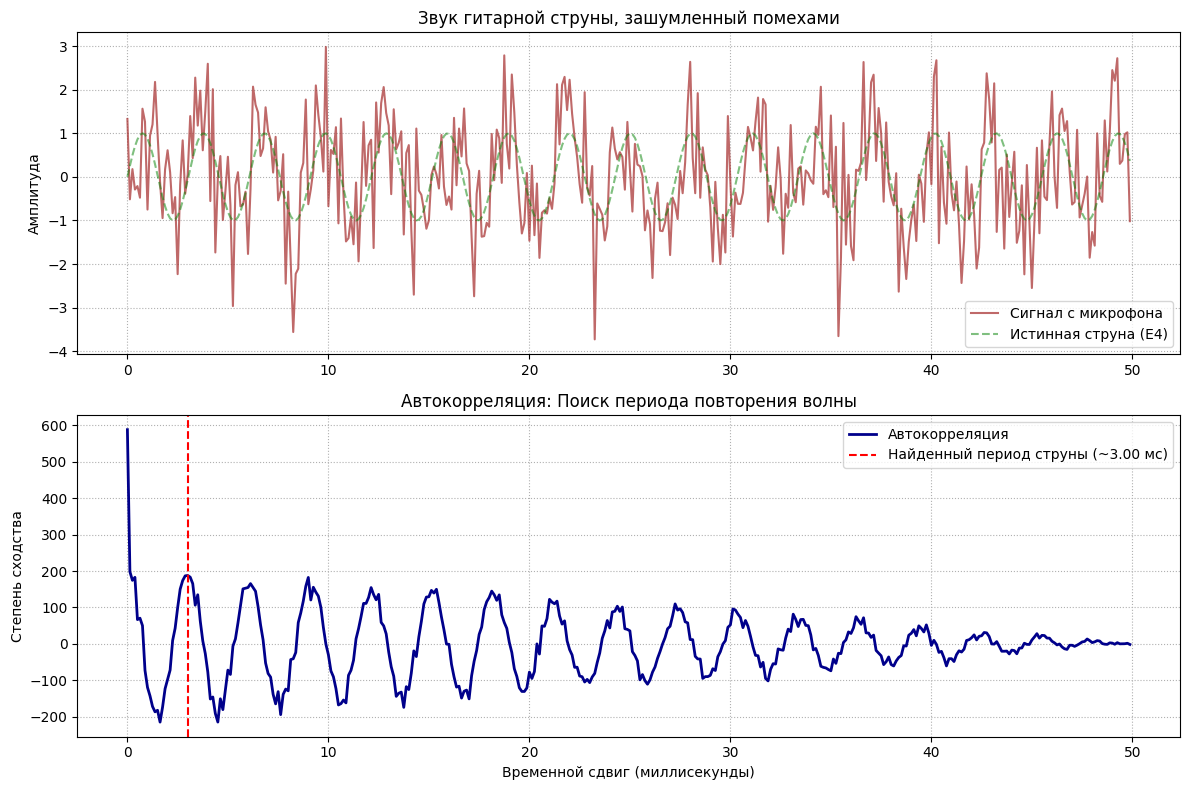

--- РЕЗУЛЬТАТ РАБОТЫ ЦОС-ТЮНЕРА ---
Реальная частота струны: 329.63 Гц
Определенная частота алгоритмом: 333.33 Гц
Погрешность измерения: 3.70 Гц


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. СИМУЛЯЦИЯ ЗВУКА ГИТАРНОЙ СТРУНЫ
# ==========================================
f_sampling = 8000  # Частота дискретизации звука (8 кГц достаточно для тюнера)
t_end = 0.05  # Запишем короткий кусочек звука (50 миллисекунд)
t = np.arange(0, t_end, 1 / f_sampling)

# Генерируем чистую ноту Ми (E4) = 329.63 Гц
f_guitar_string = 329.63
u_clean_string = np.sin(2 * np.pi * f_guitar_string * t)

# Добавляем сильный фоновый шум (гул, шорохи микрофона)
np.random.seed(24)
noise = np.random.normal(0, 1.0, len(t))
u_noisy_guitar = u_clean_string + noise

# ==========================================
# 2. АЛГОРИТМ АВТОКОРРЕЛЯЦИИ (ЦОС)
# ==========================================
N = len(u_noisy_guitar)
autocorr = np.zeros(N)

# Вычисляем автокорреляцию для каждого сдвига (лага)
for m in range(N):
    # Перемножаем сигнал со сдвинутой копией и суммируем
    if m == 0:
        autocorr[m] = np.sum(u_noisy_guitar * u_noisy_guitar)
    else:
        autocorr[m] = np.sum(u_noisy_guitar[m:] * u_noisy_guitar[:-m])

# ==========================================
# 3. ОПРЕДЕЛЕНИЕ ЧАСТОТЫ (ЛОГИКА ТЮНЕРА)
# ==========================================
# Игнорируем главный пик при нулевом сдвиге (m=0) и ищем первый локальный максимум.
# Чтобы не споткнуться о мелкий шум, начнем поиск пика, пропустив первые несколько лагов.
min_lag = int(f_sampling / 1000)  # Пропускаем частоты выше 1000 Гц (там нот гитары нет)

# Находим индекс максимального значения автокорреляции после min_lag
detected_lag = np.argmax(autocorr[min_lag:]) + min_lag

# Рассчитываем частоту
detected_period = detected_lag / f_sampling
detected_frequency = 1 / detected_period

# ==========================================
# 4. ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# График 1: Исходная шумная аудиозапись
ax1.plot(t * 1000, u_noisy_guitar, color="brown", alpha=0.7, label="Сигнал с микрофона")
ax1.plot(
    t * 1000,
    u_clean_string,
    color="green",
    linestyle="--",
    alpha=0.5,
    label="Истинная струна (E4)",
)
ax1.set_title("Звук гитарной струны, зашумленный помехами")
ax1.set_ylabel("Амплитуда")
ax1.grid(True, linestyle=":")
ax1.legend()

# График 2: Автокорреляционная функция
lags_ms = (np.arange(N) / f_sampling) * 1000  # Переводим лаги в миллисекунды
ax2.plot(lags_ms, autocorr, color="darkblue", linewidth=2, label="Автокорреляция")
ax2.axvline(
    detected_period * 1000,
    color="red",
    linestyle="--",
    label=f"Найденный период струны (~{detected_period*1000:.2f} мс)",
)
ax2.set_title("Автокорреляция: Поиск периода повторения волны")
ax2.set_xlabel("Временной сдвиг (миллисекунды)")
ax2.set_ylabel("Степень сходства")
ax2.grid(True, linestyle=":")
ax2.legend()

plt.tight_layout()
plt.show()

# Вывод результатов в консоль
print(f"--- РЕЗУЛЬТАТ РАБОТЫ ЦОС-ТЮНЕРА ---")
print(f"Реальная частота струны: {f_guitar_string} Гц")
print(f"Определенная частота алгоритмом: {detected_frequency:.2f} Гц")
print(f"Погрешность измерения: {abs(f_guitar_string - detected_frequency):.2f} Гц")


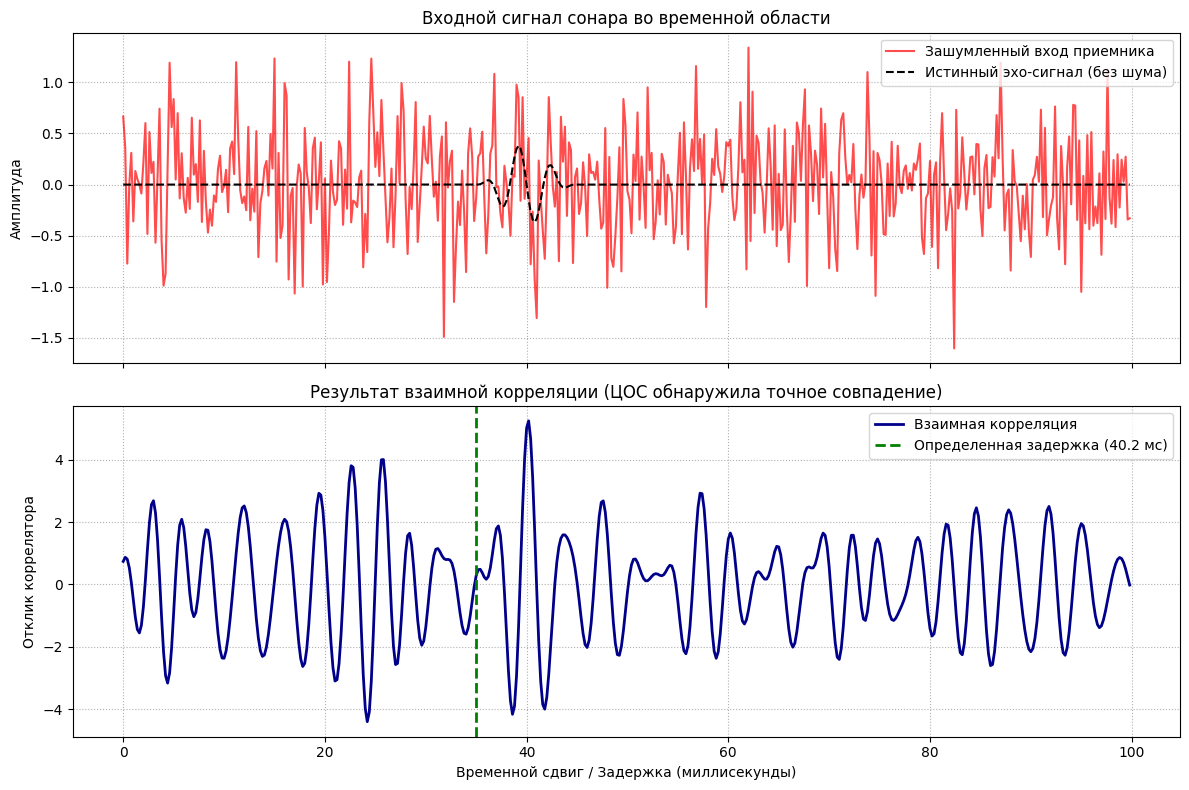

--- Результаты локации ---
Заданная физическая задержка: 35 мс
Обнаруженная алгоритмом задержка: 40.2 мс


In [11]:

# 1. Параметры времени и дискретизации
f_sampling = 5000  # 5 кГц
t_total = 0.1      # Моделируем 100 мс общего времени
t = np.arange(0, t_total, 1 / f_sampling)
N = len(t)

# 2. Создаем эталонный импульс (шаблон датчика)
# Пачка синуса 300 Гц длительностью 10 мс сглаженная окном Хэннинга
f_pulse = 300
t_pulse = np.arange(0, 0.01, 1 / f_sampling)
pulse_template = np.sin(2 * np.pi * f_pulse * t_pulse) * np.hanning(len(t_pulse))

# 3. Формируем принятый сигнал (Эхо вернулось через 35 мс)
target_delay_ms = 35
delay_samples = int((target_delay_ms / 1000) * f_sampling)

received_signal = np.zeros(N)
received_signal[delay_samples : delay_samples + len(pulse_template)] = pulse_template * 0.4

# Добавляем жесткий шум
np.random.seed(10)
noise = np.random.normal(0, 0.5, N)
u_noisy_input = received_signal + noise

# 4. ВЗАИМНАЯ КОРРЕЛЯЦИЯ (CROSS-CORRELATION)
# Функция correlate сдвигает шаблон вдоль зашумленного сигнала
# Режим 'same' возвращает массив того же размера, что и входной сигнал
cross_corr = np.correlate(u_noisy_input, pulse_template, mode='same')

# Находим индекс максимального совпадения
detected_sample = np.argmax(cross_corr)
detected_delay_ms = (detected_sample / f_sampling) * 1000

# ==========================================
# 5. ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Верхний график: То, что пришло на микрофон/приемник
ax1.plot(t * 1000, u_noisy_input, color="red", alpha=0.7, label="Зашумленный вход приемника")
ax1.plot(t * 1000, received_signal, color="black", linestyle="--", linewidth=1.5, label="Истинный эхо-сигнал (без шума)")
ax1.set_title("Входной сигнал сонара во временной области")
ax1.set_ylabel("Амплитуда")
ax1.grid(True, linestyle=":")
ax1.legend(loc="upper right")

# Нижний график: Выход алгоритма взаимной корреляции
ax2.plot(t * 1000, cross_corr, color="darkblue", linewidth=2, label="Взаимная корреляция")
ax2.axvline(target_delay_ms, color="green", linestyle="--", linewidth=2, 
            label=f"Определенная задержка ({detected_delay_ms:.1f} мс)")
ax2.set_title("Результат взаимной корреляции (ЦОС обнаружила точное совпадение)")
ax2.set_xlabel("Временной сдвиг / Задержка (миллисекунды)")
ax2.set_ylabel("Отклик коррелятора")
ax2.grid(True, linestyle=":")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"--- Результаты локации ---")
print(f"Заданная физическая задержка: {target_delay_ms} мс")
print(f"Обнаруженная алгоритмом задержка: {detected_delay_ms:.1f} мс")


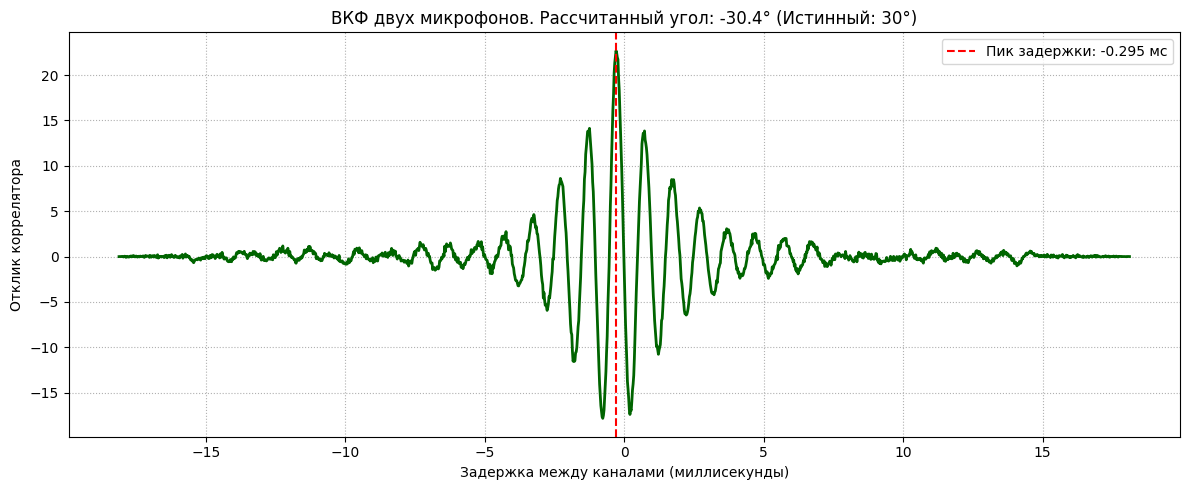

In [16]:
from scipy.signal import correlate

# 1. Физические параметры системы
v_sound = 343.0  # Скорость звука в воздухе (м/с)
d_mic = 0.20     # Расстояние между микрофонами (20 см)
f_sampling = 44100  # Студийная частота дискретизации (44.1 кГц)

# 2. Моделируем сигнал (человек сказал короткое "А")
t = np.arange(0, 0.01, 1 / f_sampling)
source_signal = np.sin(2 * np.pi * 1000 * t) * np.exp(-500 * t)  # затухающий синус 1 кГц

# Задаем реальный угол источника: например, 30 градусов относительно центральной оси
true_angle_deg = 30
true_angle_rad = np.radians(true_angle_deg)

# Вычисляем физическую задержку времени по формуле: dt = (d * sin(theta)) / v
true_dt = (d_mic * np.sin(true_angle_rad)) / v_sound
delay_samples = int(round(true_dt * f_sampling))

# Генерируем два канала (Микрофон 1 и Микрофон 2 с задержкой)
mic_left = np.zeros(800)
mic_right = np.zeros(800)

mic_left[100 : 100 + len(source_signal)] = source_signal
mic_right[100 + delay_samples : 100 + delay_samples + len(source_signal)] = source_signal

# Добавим немного шума в оба канала
np.random.seed(42)
mic_left += np.random.normal(0, 0.1, len(mic_left))
mic_right += np.random.normal(0, 0.1, len(mic_right))

# 3. ЦОС: Взаимная корреляция для поиска задержки
# Используем метод GCC-PHAT в упрощенном виде или обычную xcorr на чистом импульсе
cc = correlate(mic_left, mic_right, mode='full')
lags = np.arange(-len(mic_left) + 1, len(mic_left))

# Находим сдвиг, при котором совпадение максимально
estimated_lag = lags[np.argmax(cc)]
estimated_dt = estimated_lag / f_sampling

# 4. Расчет угла из найденной задержки: sin(theta) = (dt * v) / d
# Защищаем арксинус от ошибок округления ограничением диапазона [-1, 1]
sin_theta = (estimated_dt * v_sound) / d_mic
sin_theta = np.clip(sin_theta, -1.0, 1.0)
estimated_angle_deg = np.degrees(np.arcsin(sin_theta))

# ==========================================
# 5. ВИЗУАЛИЗАЦИЯ
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(lags / f_sampling * 1000, cc, color="darkgreen", linewidth=2)
plt.axvline(estimated_dt * 1000, color="red", linestyle="--", 
            label=f"Пик задержки: {estimated_dt*1000:.3f} мс")
plt.title(f"ВКФ двух микрофонов. Рассчитанный угол: {estimated_angle_deg:.1f}° (Истинный: {true_angle_deg}°)")
plt.xlabel("Задержка между каналами (миллисекунды)")
plt.ylabel("Отклик коррелятора")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()